In [424]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import streamlit as st
import plotly.graph_objects as go

In [425]:
RUTA_DATOS = "./datasets_limpios/" 

In [426]:
eventos = pd.read_excel(fr"{RUTA_DATOS}eventosWC26.xlsx")
partidos = pd.read_excel(fr"{RUTA_DATOS}partidosWC26.xlsx")
jugadores = pd.read_excel(fr"{RUTA_DATOS}jugadoresWC2026.xlsx")


ANÁLISIS 1. Ventanas de Partidos

In [ ]:

ORDEN_RONDAS = ["Group Stage", "Round of 32", "Round of 16", "Quarter-finals", "Semi-finals", "Third-place match", "Final"]

In [ ]:
# pesos de la métrica agregada (sobre valores por 90'). goles+asistencias NO cuenta porque ya es la suma de las otras dos
PESOS_METRICA_AGREGADA = {
    "goles_por_minuto": 1.0,
    "asistencias_por_minuto": 0.6,
    "tarjetas_amarillas_por_minuto": -0.15,
    "tarjetas_rojas_por_minuto": -0.5,
    "goles_concedidos_por_minuto": -0.3,  # esta metrica solo afecta a porteros
}

# y los nombres de las metricas para usar como labels en las graficas
NOMBRES_METRICAS = {
    "goles_por_minuto": "Goles por 90'",
    "goles_asistencias_por_minuto": "Goles + asistencias por 90'",
    "asistencias_por_minuto": "Asistencias por 90'",
    "goles_concedidos_por_minuto": "Goles concedidos por 90' (porteros)",
    "tarjetas_amarillas_por_minuto": "Tarjetas amarillas por 90'",
    "tarjetas_rojas_por_minuto": "Tarjetas rojas por 90'",
    "metrica_agregada": "Métrica agregada (puntos por 90')",
}

ORDEN_POSICIONES = ["GK", "DEF", "MID", "FWD"]

# mismo color para la misma posición en todos los gráficos
COLORES_POSICION = {"GK": "#f39c12", "DEF": "#3498db", "MID": "#2ecc71", "FWD": "#e74c3c"}


In [430]:
def preparar_jugadores():

    ### añade al dataframe de jugadores las métricas por minuto, la métrica agregada, el ranking en valor de mercado y el identificador
    df = jugadores.copy()   #con una copia para no modificar el original

    #solo nos interesan los jugadores que tienen minutos
    df = df[df["minutos_jugados"]> 0].copy()

    # los NaN en goles/asistencias/tarjetas son jugadores sin minutos segun vimos en el primero bloque luego los ponemos a 0
    for col in ["goles", "asistencias", "tarjetas_amarillas", "tarjetas_rojas"]:
        df[col] = df[col].fillna(0)

    minutos = df["minutos_jugados"].where(df["minutos_jugados"] > 0)  # evita dividir entre 0: solo conserva los valores de mminutos no nulos, y si hay nulos, los convierte en nan

    #creamos las columnas nuevas con las metricas

    df["goles_por_minuto"] = df["goles"] / minutos
    df["goles_asistencias_por_minuto"] = (df["goles"] + df["asistencias"]) / minutos
    df["asistencias_por_minuto"] = df["asistencias"] / minutos
    df["goles_concedidos_por_minuto"] = df["goles_concedidos"] / minutos # será NaN para jugadores de campo porque solo aplica allos portaros esta métrica
    df["tarjetas_amarillas_por_minuto"] = df["tarjetas_amarillas"] / minutos
    df["tarjetas_rojas_por_minuto"] = df["tarjetas_rojas"] / minutos

    
    # métrica agregada (por 90 minutos); el NaN de goles concedidos cuenta como 0 en jugadores de campo
    df["metrica_agregada"] = 0
    for metrica, peso in PESOS_METRICA_AGREGADA.items():
        df["metrica_agregada"] += 90 * peso * df[metrica].fillna(0)
    df["metrica_agregada"] = df["metrica_agregada"].where(minutos.notna())

    # rpermite crear un anking en valor de mercado entre los jugadores del Mundial que han jugado algun minuto (1 = el más caro) y gestiona loss empates
    df["ranking_valor"] = df["valor_mercado"].rank(ascending=False, method="min").astype(int)

    df["ha_marcado"] = df["goles"] > 0
    df["jugador_y_seleccion"] = df["nombre_jugador"] + " (" + df["seleccion_nacional"] + ")"

    return df

datos_jugadores = preparar_jugadores()

In [431]:
MIN_MINUTOS = 180
def filtrar_jugadores(selecciones: list =None, posiciones: list =None, num_partidos_jugados: list =None, min_minutos=MIN_MINUTOS):
    jugadores_seleccionados = datos_jugadores.copy()

    mascara_minutos_jugados = jugadores_seleccionados["minutos_jugados"]>=min_minutos
    jugadores_seleccionados = jugadores_seleccionados.loc[mascara_minutos_jugados].copy()

    if selecciones:
        mascara_seleccion = jugadores_seleccionados["seleccion_nacional"].isin(selecciones)
        jugadores_seleccionados = jugadores_seleccionados.loc[mascara_seleccion].copy()

    if num_partidos_jugados:
        minimo, maximo = num_partidos_jugados
        mascara_num_partidos = jugadores_seleccionados["partidos_jugados"].between(minimo, maximo)
        jugadores_seleccionados = jugadores_seleccionados.loc[mascara_num_partidos].copy()

    if posiciones:
        mascara_posicion = jugadores_seleccionados["posicion"].isin(posiciones)
        jugadores_seleccionados = jugadores_seleccionados.loc[mascara_posicion].copy()

    return jugadores_seleccionados


## APARTADO 2: RENDIMIENTO DE JUGADORES CLAVE

In [449]:
#esto es para el punto 5 pero lo ponemos aqui para poderlo utlizar por otras funciones

def top_jugadores_metrica(metrica="metrica_agregada", n=15, selecciones=None, posiciones=None, min_minutos=MIN_MINUTOS):
    # devuelve el top n de jugadores en la métrica escogida (con su ranking en valor de mercado)
    df = filtrar_jugadores(selecciones, posiciones, None, min_minutos).dropna(subset=[metrica])

    # las métricas por minuto se muestran por 90' que caLculamos; la agregada ya está en por 90'
    if metrica == "metrica_agregada":
        df["valor_metrica"] = df[metrica] 
    else:
        df["valor_metrica"] = df[metrica] * 90

    return df.sort_values(by = ["valor_metrica", "minutos_jugados"], ascending=[False, False]).head(n)

### 4) grafico de dispersion

In [450]:
def scatter_valor_vs_calidicacion(seleccion=None, num_partidos_jugados=None, posicion=None):
    jugadores_seleccionados = filtrar_jugadores(selecciones=seleccion, posiciones = posicion , num_partidos_jugados = num_partidos_jugados)

    mat_corr = jugadores_seleccionados[["valor_mercado", "calificacion_media"]].corr()      #calculamos la matriz de coeficientes de correlacion lineal entre calificacion y valor de los jugadores filtrados
    corr = f'{mat_corr.iloc[0, 1]:.2f}'

    if seleccion:
        texto_titulo = seleccion
    else:
        texto_titulo = ""

    #pintar un scatter de valor vs calidicacion
    fig = px.scatter(
        data_frame=jugadores_seleccionados,
        x = "valor_mercado",
        y = "calificacion_media",
        color="posicion",
        hover_name="nombre_jugador",
        hover_data={"seleccion_nacional": True, "posicion": True, "minutos_jugados": True, "partidos_jugados": True, "valor_mercado": ":.1f", "calificacion_media": ":.2f"},
        labels={
                    "valor_mercado": "Valor de Mercado (M€)",
                    "calificacion_media": "Calificación Media",
                    "posicion": "Posición",
                    "seleccion_nacional": "Selección",
                    "minutos_jugados": "Minutos",
                    "partidos_jugados": "Partidos"
                },
        color_discrete_sequence= px.colors.qualitative.Plotly,
        title=f"Valor de Mercado vs Calificación Media {texto_titulo} (coef correlación: {corr})"
    )

    return fig
    


In [451]:
scatter_valor_vs_calidicacion(seleccion=["France"])

In [452]:
scatter_valor_vs_calidicacion()

vamos a calcular correlaciones entre valor de mercado y calificacion segun diferentes grupos: por posicion, por seleccion.... y finalmente ver si hay coincidencia real entre als dos

In [453]:

def correlacion(df):
    # funcion auxiliar que nos permite calcular los coeficientes de correlacion lineal de pearson entre valor y calficacion 
    return df["valor_mercado"].corr(df["calificacion_media"])


def tabla_correlaciones_por_posicion():                    # CALCULA PARA TODAS LAS POSICIONES POSIBLES (portero defensa, centro, delanytero..) cual es la correlacion entre su valor de mercado y su calificacion

    filas = {"TODAS": correlacion(filtrar_jugadores())}

    for pos in ORDEN_POSICIONES:    #voy recorriendo las posiciones y calculando su coef
        filas[pos] = correlacion(filtrar_jugadores(posiciones=[pos]))


    return pd.DataFrame.from_dict(filas, orient="index", columns=["pearson"]).round(2)


def tabla_correlaciones_por_seleccion():    # CALCULA PARA TODAS LAS SELECCIONES POSIBLES (España, Francia, Ghana etc) cual es la correlacion entre su valor de mercado y su calificacion y las ordena 

    df = filtrar_jugadores()

    tabla = df.groupby("seleccion_nacional").apply(correlacion)
    tabla = tabla.sort_values(ascending=False).round(2)

    return pd.DataFrame(tabla).rename(columns={0: "pearson"})


def coincidencia_top_valor(metricas=["metrica_agregada"], n=15, selecciones=None, posiciones=None, min_minutos=MIN_MINUTOS):
    # ¿coinciden los más valiosos con los de mejor rendimiento?

    resultados = {}

    for metrica in metricas:
        top = top_jugadores_metrica(metrica, n, selecciones, posiciones, min_minutos)       #primero elijo los n mejeres jugadores segun la metrica que se quiera (la agregada por ejemplo)
        df = filtrar_jugadores(selecciones, posiciones, None, min_minutos).dropna(subset=[metrica])     #luego cojo todos los jugadores con los fgiltros que queremos (quitando los que no tienen valor en esa metrica)
        
        resultados[metrica]= {"en_top15_valor": int((top["ranking_valor"] <= 15).sum()),      #contamos: cuantos de los n mejores jugadores segun la metrica que hemos elegido están también entre los 15 mejor pagados?
                "en_top50_valor": int((top["ranking_valor"] <= 50).sum()),      # y lo mismo entre los 50 mejor pagados

                "mediana_ranking_valor": float(top["ranking_valor"].median()),      #vemos: entre los n mejores jugadores segun la metrica elegida, nos fijamos en sus respectivos valores de mercado, y vemos cual es la media de esos valores 
                "correlacion_metrica_valor": round(df[metrica].corr(df["valor_mercado"]), 2)}      #y finalmente vemos el valor de la correlacion entre la metrica y el valor de mercado

    return pd.DataFrame(resultados).T


In [454]:
tabla_correlaciones_por_posicion()

,pearson
TODAS,0.31
GK,0.18
DEF,0.29
MID,0.22
FWD,0.42


In [455]:
tabla_correlaciones_por_seleccion().head()

/var/folders/lx/9synkbf173d0sq0bh4fdj7sc0000gn/T/ipykernel_1137/3489824080.py:21: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,pearson
seleccion_nacional,
Norway,0.75
France,0.69
England,0.64
Jordan,0.64
South Korea,0.60


In [456]:
tabla_correlaciones_por_seleccion().tail(11)

/var/folders/lx/9synkbf173d0sq0bh4fdj7sc0000gn/T/ipykernel_1137/3489824080.py:21: DeprecationWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



,pearson
seleccion_nacional,
Spain,-0.27
Australia,-0.27
Argentina,-0.30
Cabo Verde,-0.32
Uzbekistan,-0.35
Netherlands,-0.37
Algeria,-0.38
Mexico,-0.42
Saudi Arabia,-0.61


In [457]:
datos_jugadores

,nombre_jugador,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,...,goles_por_minuto,goles_asistencias_por_minuto,asistencias_por_minuto,goles_concedidos_por_minuto,tarjetas_amarillas_por_minuto,tarjetas_rojas_por_minuto,metrica_agregada,ranking_valor,ha_marcado,jugador_y_seleccion
0,José Raúl Rangel,Mexico,CD Guadalajara,15,GK,8.9336,5,438,0.0,0.0,...,0.0,0.000000,0.000000,0.006849,0.000000,0.000000,-0.184932,460,False,José Raúl Rangel (Mexico)
1,Jorge Eduardo Sanchez,Mexico,PAOK Saloniki,59,DEF,24.6286,4,349,0.0,1.0,...,0.0,0.002865,0.002865,NaN,0.002865,0.000000,0.116046,219,False,Jorge Eduardo Sanchez (Mexico)
2,César Jasib Montes,Mexico,FC Lokomotiv Moscow,69,DEF,10.9126,4,315,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.000000,0.003175,-0.142857,405,False,César Jasib Montes (Mexico)
3,Edson Omar Alvarez,Mexico,Fenerbahçe SK,100,DEF,10.8759,4,239,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.004184,0.000000,-0.056485,406,False,Edson Omar Alvarez (Mexico)
4,Johan Felipe Vasquez,Mexico,Genoa CFC,47,DEF,18.2654,4,360,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.002778,0.000000,-0.037500,283,False,Johan Felipe Vasquez (Mexico)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1241,Anibal Casis Godoy,Panama,San Diego FC,160,MID,3.7063,1,1,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,739,False,Anibal Casis Godoy (Panama)
1243,Orlando Mosquera,Panama,Al Fayha FC,50,GK,0.7000,3,270,0.0,0.0,...,0.0,0.000000,0.000000,0.014815,0.000000,0.000000,-0.400000,982,False,Orlando Mosquera (Panama)
1244,Michael Amir Murillo,Panama,Be ş ikta ş JK,94,DEF,7.8302,3,270,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,503,False,Michael Amir Murillo (Panama)
1245,Azarías Emmanuel Londono,Panama,CD Universidad Católica,13,FWD,4.4904,3,53,0.0,0.0,...,0.0,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,688,False,Azarías Emmanuel Londono (Panama)


In [458]:
coincidencia_top_valor(metricas=["goles_asistencias_por_minuto", "metrica_agregada"])

,en_top15_valor,en_top50_valor,mediana_ranking_valor,correlacion_metrica_valor
goles_asistencias_por_minuto,5.0,7.0,81.0,0.35
metrica_agregada,4.0,6.0,94.0,0.35


OBSERVACIONES Y CONCLUSION DE ESTE PUNTO:

    -la correlacion global entre el valor de mercado y la calificación recibida tiene una relacion lineal directa positiva, pero es débil, de 0.31. Esto se debe a que la calificacion mide lo que hizo el jugador durante el mundial (en unos 3 a 8 partidos), pero el valor de mercado tiene en cuenta muchas otras cosas: en que equipo o liga juega, que edad tiene, que fama tiene, que potencial tiene etc

    - por otro lado, la posicion en la que hay una mayor correlacion entre el vaklor de mercado y su calificación en la de los DELANTEROS (coef 0.42) : en ataque el mercado y el rendimiento (más goles = más protagonismo) se parecen más; pero en portería (coef 0.18) esto pasa más desapercibido...

    -algo muy interesante si nos fijamos en a correlacion entre valor de mercado y calificacion es su gran variabilidad: por un lado, Francia, Inglaterra (coefs 0.69, 0.64, muy altos): sus estrellas rinden!!
    Otros, como Ghana (−0,63), Curaçao (−0,61), Arabia Saudí (−0,61) y México (−0,42) las tienen negativas: sus jugadores más caros rindieron peor que los baratos.
    Y el caso de españa, con una correlacion lineal entre valor de sus jugadores y calificación de -0.27, que es negativa!...

    -fijandonos en los scatter más arriba, se ven jugadores destacados: los mejores casos de valor alto + calificación alta son Mbappé (180 M€, 8,24) y Haaland (200 M€, 7,90). Y el caso curioso de Messi (calificacion8,79), que vale mucho menos de lo que rinde!!

    -pregunta: ¿coincide la relacion entre rendimiento-valor y la de calificacion-valor? La correlación calificación-valor (0,31) es casi idéntica a la de rendimiento-valor (0,35). Las dos medidas distintas de “rendir” son coherentes entre ellas!! y dan el mismo mensaje: el mercado explica poco el rendimienro que luego acaban teniendo los jugadores...

    -y finalmente y a modo de curiosidad, hemos visto: si tomamos los mejores jugadores segun la metrica agreagda, cuantos de ellos están también entre los 15 mejor pagados? -> 4 (5 para goles+asist), y entre los 50 mejor pagados? -> 6 (7 para goles + asists): es decir, coincide con decir que hay una cierta correlacion lineal pero debil entre valor y calificacion (la mediana del ranking de valor de mercado para los 15 de mejor performance es 94, muy abajo en el ranking! )

    
    Hay jugadores baratos que rinden mucho: Messi (331º en valor, 8 goles + 4 asistencias), PERO también hay caros que sí cumplen: Mbappé (3º), Haaland (1º), Bellingham (8º), Saka (12º), Olisé (4º)

    -hay que tener cuidado con la métrica agregada: el top 15 son 13 delanteros y 2 centrocampistas, y ningún defensa ni portero, por lo que la metrica agreagda les favorece. Habría que tener en cuenta muchas otras facetas del juego (participacion, pases acertados, recuperacion de balones etc que no es posible computar con las bases de datos oficiales...). 
    Por ejemplo a los porteros solo se les penaliza (si les meten goles), pero no se les da pountos ni por paradas ni por menos goles en contra....Así que el mejor portero del torneo, Unai Simón (−0,036), nunca puede aparecer en el top.... La métrica mide ataque; la defensa es invisible para los datos. Por eso en el top conviene filtrar por posición


ULTIMAS OBSERVACIONES SOBRE ESPAÑA:
    Parece raro que si españa ganó el mundial que no salga en el top 15 de mejores jugadores segun la metrica agreagda ningun espñaol, ¿Por qué no sale España? Los datos dan una respuesta clara:

    España ganó el Mundial con 22 puntos en 8 partidos y solo 1 gol encajado, la mejor defensa del torneo! (0,125 goles encajados por partido), y el mayor valor de mercado agregado (1.814 M€).

    PERO España marcó 1,75 goles por partido, bastante menos que Francia, Inglaterra o Argentina. Su ventajano eran tanto los goles, como la defensa y el colectivo, y la métrica general solo premia goles y asistencias... asi que los puntos fuertes de españa como su solidez y defensa no se ven tan reflejados por la metrica, pasan desapercibidos....

    Su mejor jugador en la métrica es Merino, puesto 20º (2 goles en 194 minutos), luego Oyarzabal, 27º. 
    En conclusion, España es un éxito colectivo y defensivo que las métricas individuales no reflejan. Por ejemplo Pedri (150 M€, 6,66, 0 goles) o Yamal (200 M€, 7,16, 1 gol) lo ilustran: contribuyeron al título sin números ofensivos destacables.

    Aquí existiría una opcion, que consiste en modificar la métrica agregada por ejemplo añadiendo peso por ganar el equipo y por no encajar muchos goles (por ejemplo (+0,3 × puntos del equipo por partido, y −0,5 × goles encajados por partido para GK y DEF)) lo cual le daria mas ventaja a los espñañoles

    El problema con esta version es que mezclaría  rendimiento individual con éxito colectivo (todos los compañeros reciben el mismo bonus aunque jueguen pocos minutos) y los porteros y defensas siguen penalizados aún añadiendo esto, así que lo dejamos simplemente como opcion

In [459]:
#los 3 mejores porteros, aquí si que sale refleajo unai!
top_jugadores_metrica(posiciones=["GK"]).head(3)

,nombre_jugador,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,...,goles_asistencias_por_minuto,asistencias_por_minuto,goles_concedidos_por_minuto,tarjetas_amarillas_por_minuto,tarjetas_rojas_por_minuto,metrica_agregada,ranking_valor,ha_marcado,jugador_y_seleccion,valor_metrica
750,Unai Simon,Spain,Athletic Club,59,GK,108.528400,8,750,0.0,0.0,...,0.0,0.0,0.001333,0.0,0.0,-0.03600,13,False,Unai Simon (Spain),-0.03600
1129,Camilo Andres Vargas,Colombia,Atlas FC,43,GK,17.816000,5,480,0.0,0.0,...,0.0,0.0,0.002083,0.0,0.0,-0.05625,299,False,Camilo Andres Vargas (Colombia),-0.05625
1040,Diogo Diogo Costa,Portugal,FC Porto,44,GK,41.901091,5,450,0.0,0.0,...,0.0,0.0,0.006667,0.0,0.0,-0.18000,107,False,Diogo Diogo Costa (Portugal),-0.18000


como un último apunte, ahora que hemos visto que el valor de mercado no acaba de explicar bien del todo ni el rendimiento individual ni las valoraciones individuales; vamos a agrupar por selecciiones y ver que pasa 

In [460]:
def corr_valor_puntos_por_seleccion():
    # me cojo las columnas que me interesan que son el resultado y el um de goles y los concateno una debajo de otra en un df (asi se pueden calcular los puntos de cada seleccion ya se alocal o visitante)
    local = partidos[["seleccion_local", "marcador_local", "marcador_visitante"]]
    local.columns = ["seleccion", "goles_favor", "goles_contra"]

    visitante = partidos[["seleccion_visitante", "marcador_visitante", "marcador_local"]]
    visitante.columns = ["seleccion", "goles_favor", "goles_contra"]

    resultados = pd.concat([local, visitante])

    #ahora que ya tengo el df calculo para cada partidos los puntos que se llevaria cada equupo
    # victoria = 3 puntos, empate = 1, derrota = 0
    resultados["puntos"] = 0
    resultados.loc[resultados["goles_favor"] > resultados["goles_contra"], "puntos"] = 3
    resultados.loc[resultados["goles_favor"] == resultados["goles_contra"], "puntos"] = 1

    #agrupamos por seleccion y contamos los puntos hecho por esa seleccion, num partidos jugados, goles recibidos etc
    tabla_equipos = resultados.groupby("seleccion").agg(
        partidos=("puntos", "size"),
        puntos=("puntos", "sum"),
        goles_contra=("goles_contra", "sum")
    )

    tabla_equipos["puntos_por_partido"] = (tabla_equipos["puntos"] / tabla_equipos["partidos"]).round(2)    #los putos por partido es dividir puntos totales entre nuemro de partidos

    # valor de la plantilla corresponde a la suma del valor de mercado de sus jugadores
    tabla_equipos["valor_plantilla"] = datos_jugadores.groupby("seleccion_nacional")["valor_mercado"].sum().round(0)

    #representar el valor total de la plantilla vs los puntos por partido conseguidos
    fig = px.scatter(
        tabla_equipos.reset_index(),
        x="valor_plantilla",
        y="puntos_por_partido",
        text="seleccion",
        hover_name="seleccion",
        labels={
            "valor_plantilla": "Valor de la plantilla (M€)",
            "puntos_por_partido": "Puntos por partido"
        },
        title="Valor de la plantilla vs puntos por partido"
    )
    fig.update_traces(textposition="top center", marker=dict(size=11, opacity=0.8))
    return fig

corr_valor_puntos_por_seleccion()

la correlacion lineal entre el valor total de la plantilla y sus puntos por partido es :0.7648116780117032

EFECTIVAMENTE AQUI SALE ESPAÑA LA PRIMERA, LA AUE MAS PUNTOS POR PARTIDO HA HECHO DE MEDIA Y TAMBIEN LA MÁS CARA DE PLANTILLA EN TOTAL
ADEMÁS LAS 4 SELECCIONES QUE MAS LEJOS LLEGARON EN LA COMPETICION SON LAS 4 MÁS CARAS

CONCLUSION IMPORTANTE: EL VALOR INDIVIDUAL DE ERCADO DE UN JUGADOR NO EXPLICA NECESARIAMENTE (COEF APROX O.3) SU RENDIMINETO/VALORACION;; SIN EMBARGO EL VALOR DE MERCADO TOTAL DE TODO EL EQUPI SI EXPLICA MUY MUY BIEN (COEF 0.76) COMO DE BIEN JUEGA UN EQUIPO EN SIU CONJUNTO; ES DECIR, APLCIA MEJOR AL EQUIPO EN TOTAL QUE AL INDIVIDUO.

5)


In [461]:
top_jugadores_metrica()

,nombre_jugador,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,...,goles_asistencias_por_minuto,asistencias_por_minuto,goles_concedidos_por_minuto,tarjetas_amarillas_por_minuto,tarjetas_rojas_por_minuto,metrica_agregada,ranking_valor,ha_marcado,jugador_y_seleccion,valor_metrica
190,Johan Kula Manzambi,Switzerland,SC Freiburg,13,MID,50.0000,4,198,3.0,2.0,...,0.025253,0.010101,NaN,0.000000,0.0,1.909091,81,True,Johan Kula Manzambi (Switzerland),1.909091
841,Kylian Mbappe,France,Real Madrid C. F.,99,FWD,180.0000,8,698,10.0,4.0,...,0.020057,0.005731,NaN,0.001433,0.0,1.579513,3,True,Kylian Mbappe (France),1.579513
918,Erling Braut Haaland,Norway,Manchester City FC,51,FWD,200.0000,5,465,7.0,0.0,...,0.015054,0.000000,NaN,0.000000,0.0,1.354839,1,True,Erling Braut Haaland (Norway),1.354839
945,Lionel Andrés Messi,Argentina,Inter Miami CF,200,FWD,15.0000,8,740,8.0,4.0,...,0.016216,0.005405,NaN,0.000000,0.0,1.264865,331,True,Lionel Andrés Messi (Argentina),1.264865
1150,Bukayo Ayoyinka Saka,England,Arsenal FC,50,FWD,110.0000,7,358,3.0,3.0,...,0.016760,0.008380,NaN,0.000000,0.0,1.206704,12,True,Bukayo Ayoyinka Saka (England),1.206704
538,Brian Ebenezer Adjei Brobbey,Netherlands,Sunderland AFC,13,FWD,30.0000,4,225,3.0,0.0,...,0.013333,0.000000,NaN,0.000000,0.0,1.200000,166,True,Brian Ebenezer Adjei Brobbey (Netherlands),1.200000
838,Masour Ousmane Dembele,France,Paris Saint-Germain,60,FWD,100.0000,7,513,6.0,1.0,...,0.013645,0.001949,NaN,0.000000,0.0,1.157895,17,True,Masour Ousmane Dembele (France),1.157895
875,Ismaila Sarr,Senegal,Crystal Palace FC,85,FWD,40.0000,4,366,4.0,1.0,...,0.013661,0.002732,NaN,0.000000,0.0,1.131148,112,True,Ismaila Sarr (Senegal),1.131148
632,Romelu Lukaku,Belgium,SSC Napoli,127,FWD,22.0000,6,229,3.0,0.0,...,0.013100,0.000000,NaN,0.004367,0.0,1.120087,232,True,Romelu Lukaku (Belgium),1.120087
543,Crysencio Jilbert Sylverio Cir Summerville,Netherlands,West Ham United FC,3,FWD,35.0000,4,252,2.0,2.0,...,0.015873,0.007937,NaN,0.003968,0.0,1.089286,144,True,Crysencio Jilbert Sylverio Cir Summerville (Ne...,1.089286


In [462]:

def grafico_top_jugadores(metrica="metrica_agregada", n=15, selecciones=None, posiciones=None, min_minutos=MIN_MINUTOS):
    top = top_jugadores_metrica(metrica, n, selecciones, posiciones, min_minutos)
    
    top = top.iloc[::-1].copy()  # para que el nº 1 quede arriba
    top["etiqueta_ranking"] = top["ranking_valor"].astype(str) + "º en valor"

    fig = px.bar(
        data_frame=top,
        x="valor_metrica",
        y="jugador_y_seleccion",
        orientation="h",
        color="posicion",
        text="etiqueta_ranking",
        hover_data={
            "seleccion_nacional": True,
            "minutos_jugados": True,
            "valor_mercado": ":.1f",
            "ranking_valor": True,
            "valor_metrica": ":.2f",
            "jugador_y_seleccion": False,
            "etiqueta_ranking": False,
        },
        labels={
            "valor_metrica": NOMBRES_METRICAS[metrica],
            "jugador_y_seleccion": "Jugador",
            "posicion": "Posición",
            "seleccion_nacional": "Selección",
            "minutos_jugados": "Minutos",
            "valor_mercado": "Valor de Mercado (M€)",
            "ranking_valor": "Ranking valor",
        },
        color_discrete_map=COLORES_POSICION,
        category_orders={"posicion": ORDEN_POSICIONES},
        title=f"Top {len(top)} jugadores: {NOMBRES_METRICAS[metrica]} (mín. {min_minutos} minutos)",
    )
    fig.update_layout(yaxis=dict(categoryorder="array", categoryarray=top["jugador_y_seleccion"].tolist(), automargin=True))
    fig.update_traces(textposition="outside", cliponaxis=False)

    return fig

In [463]:
grafico_top_jugadores("metrica_agregada").show()

In [464]:
grafico_top_jugadores("goles_asistencias_por_minuto").show()

6)


In [465]:
def bubble_metricas(seleccion=None, posicion=None):
    jugadores_seleccionados = filtrar_jugadores(selecciones = seleccion, posiciones= posicion)

    jugadores_seleccionados = jugadores_seleccionados[(jugadores_seleccionados["minutos_jugados"]>0) & (jugadores_seleccionados["calificacion_media"]>0)].copy()          #nos quedamos solo con aquellos valores no nulos de calidficacion y minutos jugados

    jugadores_seleccionados["han_marcado"] =  "No ha marcado"
    mascara_han_marcado = jugadores_seleccionados["goles"] > 0
    jugadores_seleccionados.loc[mascara_han_marcado, "han_marcado"] = "Ha marcado"

    detalle = "de "
    if seleccion:
        detalle += str(seleccion) + " "

    if posicion:
            detalle += str(posicion)
    
    fig = px.scatter(
        data_frame=jugadores_seleccionados,
        x="minutos_jugados",
        y="calificacion_media",
        size="valor_mercado",
        color="han_marcado",
        hover_name="nombre_jugador",
        hover_data={
            "seleccion_nacional": True,
            "posicion": True,
            "goles": True,
            "valor_mercado": ":.1f",
            "calificacion_media": ":.2f",
            "minutos_jugados": True,
            "han_marcado": False,
        },
        labels={
            "minutos_jugados": "Minutos Jugados",
            "calificacion_media": "Calificación Media",
            "valor_mercado": "Valor de Mercado (M€)",
            "han_marcado": "Goleador",
            "seleccion_nacional": "Selección",
            "posicion": "Posición",
            "goles": "Goles",
        },
        #color_discrete_map={"Sobre-rendimiento": "#2ecc71", "Infra-rendimiento": "#e74c3c"},        category_orders={"marca": ["No ha marcado", "Ha marcado"]},  # los goleadores se pintan encima
        size_max=45,
        title=f"Minutos vs Calificación Media (tamaño = Valor de Mercado) {detalle}",
        color_discrete_map={"Ha marcado": "#2ecc71", "No ha marcado": "#bdc3c7"},       #atribuir los colores a si ha marcado o no
        category_orders={"han_marcado": ["No ha marcado", "Ha marcado"]},      #para que se pinten por encima los que ha marcado
    )
    fig.update_traces(marker=dict(opacity=0.7, line=dict(width=0.5, color="white")))
    return fig




    
bubble_metricas(posicion=["FWD"]).show()
#bubble_metricas()


In [466]:
bubble_metricas(posicion=["GK"]).show()

DESTACADO VOZINHA EN SU GRAN MUNDIAL!!

In [467]:
bubble_metricas(posicion=["MID"]).show()

In [468]:
bubble_metricas().show()

Lo que nos queda es valorar si han tenido un sobre o infra rendimiento. Una forma sencilla de medir ese sobre/infra-rendimiento es comparar el percentil del jugador en CALIFICACIÓN con su percentil en VALOR (0 a 1), si el percentil de CALIFICACIOn esta poor encima del de VALOR habra tenido un sobre rendimiento y en caso contrario un infra rendimiento.

In [469]:
def tabla_rendimiento_vs_valor(selecciones=None, posiciones=None, min_minutos=MIN_MINUTOS):
    # compara cuánto destaca el jugador en calificación frente a cuánto destaca en valor de mercado utilizando los percentiles (está explicado en el markdown de encima)

    df = filtrar_jugadores(min_minutos=min_minutos)     #tomar los datos


    df["pct_calificacion"] = df.groupby("posicion")["calificacion_media"].rank(pct=True)   # permite crear un ranking de calificacion (del peor al mejor calificado) en funcion de sus percentiles de calificación: (va entre 0 y 1 con 1 = la mejor calificación) agrupamos por posicion para evitar desequilibrios entre proteros ydelanteros etc
    df["pct_valor"] = df.groupby("posicion")["valor_mercado"].rank(pct=True)              # lo mismo pero para los valroes de mercado (con 1 = el más caro)
    df["diferencia"] = df["pct_calificacion"] - df["pct_valor"]        # calculamos la resta entre los dos percentiles, y si es >0 rinde más de lo que vale (sobre rendimiento)

    #aqui en funciuon de la resta, si es mayor que 0.4 habra sobre rendimiento, menor a -0.4 infrarendimiento y si no es acorde. Esos ñímites son un poco arbitrarios y se pueden ajustar...
    df["diagnostico"] = "Acorde a su valor"
    #print(np.quantile(df["diferencia"], 0.1))
    #print(np.quantile(df["diferencia"], 0.9))

    mascara_infra = df["diferencia"] < -0.4
    df.loc[mascara_infra, "diagnostico"] = "Infra-rendimiento"

    mascara_sobre = df["diferencia"] > 0.4
    df.loc[mascara_sobre, "diagnostico"] = "Sobre-rendimiento"

    if selecciones:                                       
        df = df[df["seleccion_nacional"].isin(selecciones)]
    if posiciones:
        df = df[df["posicion"].isin(posiciones)]

    df = df.sort_values("diferencia", ascending=False)
    return df

hemos tomado 0.4 como valor de límite para determinar sober e infra rendimiento, no de manera arbitraria, sino porque hemos visto que lso percentiles 10/15 y 85/90 corresponden aproximadamente a +/- 0.4, por lo que 0.4 marca de manera aproximada el 10% de los valores de diferencia más extremos por cada lado

In [470]:
tabla_rendimiento_vs_valor()

,nombre_jugador,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,...,tarjetas_amarillas_por_minuto,tarjetas_rojas_por_minuto,metrica_agregada,ranking_valor,ha_marcado,jugador_y_seleccion,pct_calificacion,pct_valor,diferencia,diagnostico
290,Grant Campbell Hanley,Scotland,Hibernian FC,69,DEF,0.2000,2,180,0.0,0.0,...,0.000000,0.000000,0.000000,1026,False,Grant Campbell Hanley (Scotland),0.936585,0.021951,0.914634,Sobre-rendimiento
863,Ismaila Pathe Ciss,Senegal,Rayo Vallecano,32,MID,1.8000,4,181,0.0,0.0,...,0.000000,0.000000,0.000000,883,False,Ismaila Pathe Ciss (Senegal),0.960674,0.095506,0.865169,Sobre-rendimiento
712,Elijah Henry Just,New Zealand,Motherwell FC,45,MID,2.5000,3,265,3.0,0.0,...,0.003774,0.000000,0.967925,822,True,Elijah Henry Just (New Zealand),1.000000,0.148876,0.851124,Sobre-rendimiento
862,Idrissa Gana Gueye,Senegal,Everton FC,137,MID,0.5000,4,363,0.0,0.0,...,0.000000,0.000000,0.000000,997,False,Idrissa Gana Gueye (Senegal),0.859551,0.011236,0.848315,Sobre-rendimiento
1218,Derrick Luckassen,Ghana,Pafos FC,1,DEF,1.2000,2,180,1.0,0.0,...,0.000000,0.000000,0.500000,936,True,Derrick Luckassen (Ghana),0.909756,0.097561,0.812195,Sobre-rendimiento
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
857,Maxence Guy Lacroix,France,Crystal Palace FC,4,DEF,50.0000,4,330,0.0,0.0,...,0.000000,0.000000,0.000000,81,False,Maxence Guy Lacroix (France),0.151220,0.917073,-0.765854,Infra-rendimiento
961,Nahuel Molina,Argentina,Atlético De Madrid,59,DEF,105.5797,7,531,0.0,0.0,...,0.000000,0.000000,0.000000,14,False,Nahuel Molina (Argentina),0.224390,1.000000,-0.775610,Infra-rendimiento
1169,Jarell Amorin Quansah,England,Bayer 04 Leverkusen,3,DEF,45.0000,3,207,0.0,0.0,...,0.004831,0.004831,-0.282609,94,False,Jarell Amorin Quansah (England),0.087805,0.900000,-0.812195,Infra-rendimiento
1093,Abdukodir Khusanov,Uzbekistan,Manchester City FC,28,DEF,50.0000,3,270,0.0,0.0,...,0.007407,0.000000,-0.100000,81,False,Abdukodir Khusanov (Uzbekistan),0.031707,0.917073,-0.885366,Infra-rendimiento


In [471]:
#representar la tabla de sobre o infra rendimientos que acabamos de crear visualmente
def grafico_sobre_infra_rendimiento(n=10, selecciones=None, posiciones=None, min_minutos=MIN_MINUTOS):
    tabla = tabla_rendimiento_vs_valor(selecciones, posiciones, min_minutos)    #crear la tabla

    top = pd.concat([tabla.head(n), tabla.tail(n)]).drop_duplicates(subset=["jugador_y_seleccion"])     #me guardo los 10 con mas sobre rendimiento y los 10 con menos sobre rendimiento en un df top
    top = top.sort_values("diferencia")  # el mayor sobre-rendimiento queda arriba

    if selecciones:
        etq_selecciones = selecciones
    else:
        etq_selecciones = ""
    fig = px.bar(
        data_frame=top,
        x="diferencia",
        y="jugador_y_seleccion",
        orientation="h",
        color="diagnostico",
        hover_data={"seleccion_nacional": True, "posicion": True, "valor_mercado": ":.1f", "calificacion_media": ":.2f", "jugador_y_seleccion": False},
        labels={"jugador_y_seleccion": "Jugadores", "diferencia": "Pct calificacion - pct valor", "jugador": "Jugador", "diagnostico": "Diagnóstico", "seleccion_nacional": "Selección", "posicion": "Posición", "valor_mercado": "Valor de Mercado (M€)", "calificacion_media": "Calificación", "calificacion_esperada": "Esperada"},
        color_discrete_map={"Sobre-rendimiento": "#2ecc71", "Infra-rendimiento": "#e74c3c", "Acorde a su valor": "#bdc3c7"},
        title=f"Mayores sobre y infra-rendimientos respecto a su valor de mercado {etq_selecciones} (mín. {min_minutos} minutos)",
    )
    
    fig.update_layout(height=max(500, 35 * len(top)), yaxis=dict(categoryorder="array", categoryarray=top["jugador_y_seleccion"].tolist(), automargin=True))
    return fig

In [472]:
grafico_sobre_infra_rendimiento()

In [473]:
grafico_sobre_infra_rendimiento(selecciones=["Spain"])



    -Con pocos minutos hay más dispersión, pero con más minutos se concentran en 6,5-7,5.   
    -Los goleadores se concentran en las calificaciones altas, pero muchos de los de mejor calificación no marcan (porteros y defensas).


    -Sobre-rendimiento:  Just, Ciss y Gana Gueye (Senegal, medios muy baratos), Hanley...
    -Infra-rendimiento: Semenyo, Khusanov, Quansah, Molina...

    -es curioso que está Pedri (150 M€, 6,66, sin goles ni asistencias), y Ferran Torres (75,8 M€, 6,46), pero ambos no tuvieron un rendimiento individual muy bueno durante el mundial aún llegando a la final. 
    
    -Por otro lado muchas de las estrellas “cumplen”: Mbappé (+0,01), Bellingham (+0,006), Haaland (−0,03) y Dembélé (+0,04) con valores muy cercanos al 0, rinden acorde a su valor, ni sobre ni infra.

    -Argentina es un caso curioso: tiene a Messi (+0,57) y a la vez a tres de los mayores infra-rendimientos (Molina −0,78, Simeone −0,70, Álvarez −0,67), caros pero que no rindieron...
    -y por último hay que tener cuidado con los 180 minutos: por ejempl Hanley juega justo 180' y Ciss 181', es decir, unos 2 partidos. Su calificación es poco fiable.

    -fijñandonos en España, esta gráfica de sobre e infra rendimiento permite mostrar que practicamente todos ellos rindieron a su nivel Cubarsí, Rodri, Oyarzabal, Baena, Olmo, Fabián etc rindieron acorde a su nivel. Y muy pocos tuvieron infra rendiiento: Pedri por ejemplo no tuvo sus mejores partidos... Y españa, que tenía la platilla MAS CARA del mundial, sus jugadores no llegaron a rendir individualmente por encima de su precio, como veremos fue de forma global, entre todos, como ganaron.


### PARTE 3

7   : Se quiere analizar si existen patrones diferenciados en el criterio arbitral a lo largo del Mundial.

In [474]:
TIPOS_TARJETA = ["Yellow Card", "Red Card"]

In [475]:

def texto_partido(fila):
    # lo mismo, devuelve un texto descriptivo de un partido dado  de una linea (p.ej. 'Argentina 3-1 Switzerland (prórroga)')
    texto = f"{fila['seleccion_local']} {fila['marcador_local']}-{fila['marcador_visitante']} {fila['seleccion_visitante']}"
    if fila["penalty_local"] > 0 or fila["penalty_visitante"] > 0:
        texto += f" (pen. {fila['penalty_local']}-{fila['penalty_visitante']})"
    elif fila["prorroga"] == "SI":
        texto += " (prórroga)"
    return texto

In [476]:
PESOS_INDICE = {"Yellow Card": 1, "Red Card": 3, "VAR Review": 1, "Goal": 0.2}

In [477]:
def crear_tabla_partidos():
    # creamos un df con una fila para cada partido con su nombre, ronda, árbitro, nº de tarjetas etc
    df = partidos[["index_partido", "ronda", "arbitro_partido", "seleccion_local", "seleccion_visitante"]].copy()

    #pongo una columna con breve descripcion del partido y otra con el indice tambien
    df["partido"] = partidos.apply(texto_partido, axis = 1)
    df["etiqueta_partido"] = "#" + df["index_partido"].astype(str) + " " + df["partido"]

    

    # aqui: tomamos los eventos que sean tarjetas 'x', las agrupamos por partido y se cuenta cuantas hay (y en caso de que haya nan las ponemos en 0)
    conteo = eventos[eventos["tipo_evento"].isin(TIPOS_TARJETA)].groupby("index_partido").size()
    df["tarjetas"] = df["index_partido"].map(conteo).fillna(0).astype(int)
    df["amarillas"] = df["index_partido"].map(eventos[eventos["tipo_evento"] == "Yellow Card"].groupby("index_partido").size()).fillna(0).astype(int)
    df["rojas"] = df["index_partido"].map(eventos[eventos["tipo_evento"] == "Red Card"].groupby("index_partido").size()).fillna(0).astype(int)

    # creamos un índice de intervención arbitral de acuerdo a los pesos del ultimo apartado

    #seleccionamos los eventos que estan entre los pesos definidos 
    eventos_seleccionados = eventos[eventos["tipo_evento"].isin(PESOS_INDICE)].copy()
    #a cada evento le asociamos el peso correspondiente
    eventos_seleccionados["puntos"] = eventos_seleccionados["tipo_evento"].map(PESOS_INDICE)

    #finalmente, agrupamos los eventos por partido, y le asignnamos la suma de pesos del partido (redondeada) al índice de intervencion arbitral
    df["indice_intervencion"] = df["index_partido"].map(eventos_seleccionados.groupby("index_partido")["puntos"].sum()).fillna(0).round(2)
    
    return df

#dejamos creado datos_partido para reutilizarlo
datos_partidos = crear_tabla_partidos()


In [478]:
datos_partidos

,index_partido,ronda,arbitro_partido,seleccion_local,seleccion_visitante,partido,etiqueta_partido,tarjetas,amarillas,rojas,indice_intervencion
0,1,Group Stage,Wilton Sampaio,Mexico,South Africa,Mexico 2-0 South Africa,#1 Mexico 2-0 South Africa,6,3,3,13.4
1,2,Group Stage,Amin Omar,South Korea,Czechia,South Korea 2-1 Czechia,#2 South Korea 2-1 Czechia,1,1,0,1.6
2,3,Group Stage,Facundo Tello,Canada,Bosnia and Herzegovina,Canada 1-1 Bosnia and Herzegovina,#3 Canada 1-1 Bosnia and Herzegovina,5,5,0,5.4
3,4,Group Stage,Danny Makkelie,USA,Paraguay,USA 4-1 Paraguay,#4 USA 4-1 Paraguay,6,6,0,7.0
4,5,Group Stage,Saíd Martínez,Qatar,Switzerland,Qatar 1-1 Switzerland,#5 Qatar 1-1 Switzerland,3,3,0,3.4
...,...,...,...,...,...,...,...,...,...,...,...
99,100,Quarter-finals,João Pinheiro,Argentina,Switzerland,Argentina 3-1 Switzerland (prórroga),#100 Argentina 3-1 Switzerland (prórroga),5,4,1,8.8
100,101,Semi-finals,Iván Barton,France,Spain,France 0-2 Spain,#101 France 0-2 Spain,3,3,0,5.4
101,102,Semi-finals,Ismail Elfath,England,Argentina,England 1-2 Argentina,#102 England 1-2 Argentina,3,3,0,3.6
102,103,Third-place match,Jesús Valenzuela,France,England,France 4-6 England,#103 France 4-6 England,0,0,0,2.0


In [479]:
COLUMNAS_TARJETA = ["amarillas", "rojas"]

In [480]:
def grafico_boxplot_tarjetas(rondas=None, tipos_tarjeta=None):

    if tipos_tarjeta is None:
        texto_para_titulo = COLUMNAS_TARJETA
    else:
        texto_para_titulo = tipos_tarjeta

    #se cogen las rondas pedidas 
    if rondas is not None:
        df = datos_partidos[datos_partidos["ronda"].isin(rondas)].copy()
    else:
        df = datos_partidos.copy()

    def contar_num_tarjetas(row):
        num_tarjetas = 0
        for tipo_tarjeta in COLUMNAS_TARJETA:
            if tipos_tarjeta is None or tipo_tarjeta in tipos_tarjeta:
                num_tarjetas += row[tipo_tarjeta]

        return num_tarjetas

    df["n_tarjetas"] = df.apply(contar_num_tarjetas, axis = 1)

    fig = px.box(
        data_frame=df,
        x="ronda",
        y="n_tarjetas",
        color="ronda",
        points="all",  # ponemos un punto en cada partido
        hover_name="etiqueta_partido",
        hover_data={"arbitro_partido": True, "amarillas": True, "rojas": True, "ronda": False, "n_tarjetas": False},
        labels={"ronda": "Ronda", "n_tarjetas": "Tarjetas por partido", "arbitro_partido": "Árbitro", "amarillas": "Amarillas", "rojas": "Rojas"},
        title=f"Tarjetas por partido según la ronda {texto_para_titulo}",
        color_discrete_sequence= px.colors.qualitative.Plotly
    )
    fig.update_traces(jitter=0.5, pointpos=0, marker=dict(size=6, opacity=0.7))


    return fig


In [481]:
#grafico_boxplot_tarjetas(rondas=["Group Stage", "Round of 16"])
#grafico_boxplot_tarjetas(tipos_tarjeta=["amarillas"])
grafico_boxplot_tarjetas()

In [482]:
def grafico_rojas_por_ronda():
    rojas = datos_partidos.groupby("ronda")["rojas"].sum().reindex(ORDEN_RONDAS).reset_index()
    return px.bar(rojas, x="ronda", y="rojas", text_auto=True, title="Tarjetas rojas por ronda", color_discrete_sequence=["red"])
grafico_rojas_por_ronda()

In [483]:

def resumen_tarjetas_por_ronda():
    # creamos un df con la media, mediana de tarjetas y nº de partidos por ronda
    resumen = datos_partidos.groupby("ronda").agg(
        partidos=("index_partido", "count"),
        tarjetas_media=("tarjetas", "mean"),
        tarjetas_mediana=("tarjetas", "median"),
        tarjetas_max=("tarjetas", "max"),
        amarillas_total=("amarillas", "sum"),
        rojas_total=("rojas", "sum"),
    )
    resumen = resumen.reindex(ORDEN_RONDAS).round(2)        #permite ordenar segun el orden de las rondas y redondear los valores a dos decimales
    return resumen

In [484]:
resumen_tarjetas_por_ronda()

,partidos,tarjetas_media,tarjetas_mediana,tarjetas_max,amarillas_total,rojas_total
ronda,,,,,,
Group Stage,72,2.56,2.5,7,175,9
Round of 32,16,2.06,2.0,6,31,2
Round of 16,8,2.88,2.5,7,22,1
Quarter-finals,4,2.75,2.5,5,10,1
Semi-finals,2,3.00,3.0,3,6,0
Third-place match,1,0.00,0.0,0,0,0
Final,1,8.00,8.0,8,6,2


OBSERVACIONES:

-la ronda más permisiva respecto a tarjetas fue la de 32 (2.06 tarjetas de media por partido); y la más dura fue la semifinal con 3 tarjetas por partido. Pero claro, con tan pocos partidos, no se puede considerar que sea una tendencia, sino ruido de los datos...
-el caso de la final es único: tanto porque solo tenemos un ñunico dato, como porque el único dato que tenemos es el más alto del torneo: 8 tarjetas (maximo de todo el torneo): se jugaban mucho y el numero de tarjetas lo demuestra... y las rojas a Argentina ayudaron tambien. En cualquier caso es un outlier del que no se puede cdecidir nada (hay n=1 dato)
-en el partido por el tercer y cuarto puesto, está claro que no se jugaban nada y no importaba mucho, pues se pusieron 0 tarjetas; los jugadores estarían más preocupados de no hacer faltas grandes y no lesionarse...
-el boxplot no sirve para als tarjetas rojas puesto que hay muy pocas, y se ve mejor con un barplot

-alñgo a tener en cuenta es que en las eliminatorias, hay partidos en los que se jugó prorroga, y en dichos partidos, por el simple hecho de que se jugaron más minutos hay también más tarjetas.
-a primer vista, viendo las medianas parece que conforme aumenta el torneo aumenta tabien el numero mediano de atrjetas por partido
-¿pero, resulta estadisticamente significativo decir que conforma avanza la competicion, y mñás decisivos e importantes son los partidos, más tarjetas hay? ->

VERIFICACIÓN POR CONTRASTE:
hemos aplicado lo que aprendimos en año pasado en cunato a contrastes de hipotésis paramétricos, pvalores etc.
El código para realizar el contrste procede de la chuleta de PRobabilidad y estadistica del año pasado en primero.

Aplicamos el contraste de la media de una variable (varianza desconocida) por lo que nos preguntamos es “¿la media de tarjetas por partido en eliminatorias es igual a la de fase de grupos?”, con el contraste intentaremos responder a esa pregunta. 
Requisitos: para poder aplicar el test, necesitamos normalidad de los dato: las tarjetas por partido son un conteo y no son exactamente normales, pero con n=32 la media muestral es aproximadamente normal (por el teorema central del limite), y como no conocemos la varianza usamos la t de Student. En cuanto a mu_0 para el contraste, lo sacamos de la media de tarhetas de los 72 partidos de la fase de grupos (2,556); es una estimación, no un valor conocido, y lo asumimos como simplificación.


mu_0 es 2.5555555555555554
H0: hipotesis a priori: la media en la fase eliminatoria es igual a la media en la fase de grupos
n=32 | media=2.53 | mu_0=2.56 | t0=-0.061 | p-valor=0.952
El valor observado del estadistico de contraste es -0.06129747604081844, con un p-valor asociado igual a 0.9515158007658236.
No se rechaza H0 (alfa=0.05). Se verifica que pvalor = 0.9515158007658236 > alfa=  0.05 por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.


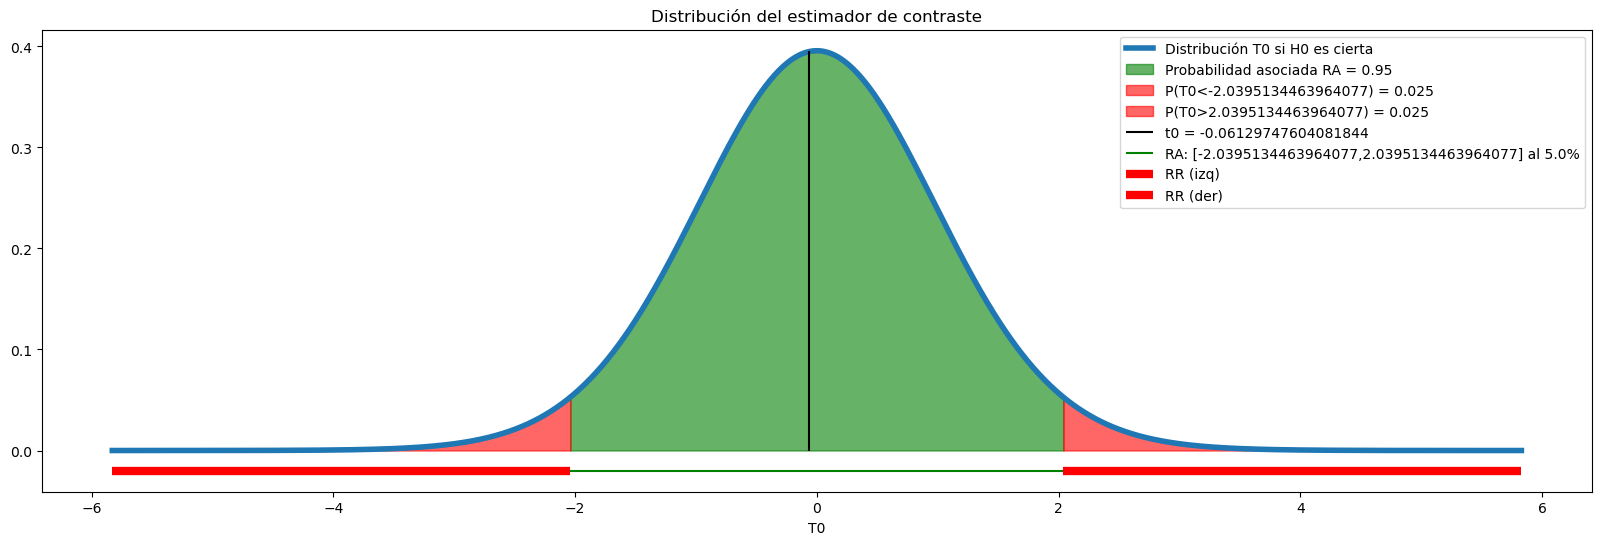

TtestResult(statistic=np.float64(-0.06129747604081844), pvalue=np.float64(0.9515158007658236), df=np.int64(31))

In [485]:
from scipy import stats

def contraste_media_two_sided(x, mu_0, alfa=0.05):

    alternativa="two-sided"
    # contraste de la media con varianza desconocida (viene de la chuleta de estadistica, cálculo directo)
    print(f'mu_0 es {mu_0}')
    print(f'H0: hipotesis a priori: la media en la fase eliminatoria es igual a la media en la fase de grupos')

    res = stats.ttest_1samp(x, popmean=mu_0, alternative=alternativa)
    print(f"n={len(x)} | media={np.mean(x):.2f} | mu_0={mu_0:.2f} | t0={res.statistic:.3f} | p-valor={res.pvalue:.3f}")

    t0 = res.statistic
    pvalor = res.pvalue

    print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')

    if pvalor < alfa:
        print(f"Se rechaza H0. Se verifica que pvalor = {pvalor} < alfa = {alfa} por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.")
    else:
        print(f"No se rechaza H0 (alfa={alfa}). Se verifica que pvalor = {pvalor} > alfa=  {alfa} por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.")


    # REPRESENTACIÓN GRÁFICA (BILATERAL) chuleta de primero
    n = len(x)
    x_media = np.mean(x)
    sx = np.std(x, ddof=1) # dividiendo por n-1

    t0 = (x_media - mu_0) / (sx/np.sqrt(n))

    # crea la distribución del estadístico de contraste
    gl = n -1 # grados de libertad
    T0 = stats.t(gl)

    # calculamos el pvalor (caso H1 BILATERAL)
    pvalor = 2 * (1 - T0.cdf(abs(t0)))

    # razonando con valores críticos
    # nivel de significación
    alfa = 0.05

    # determina los valores críticos que definen la región de rechazo (bilateral)
    t_crit_iz = T0.ppf(alfa/2)
    t_crit_de = T0.ppf(1-alfa/2)


    # puntos para representar la distribución y las regiones de aceptación y rechazo
    xmin = T0.ppf(0.000001)
    xmax = T0.ppf(1-0.000001)
    xs = np.linspace(xmin, xmax, 1000)
    xRA = np.linspace(t_crit_iz, t_crit_de, 1000)
    xRRiz = np.linspace(xmin, t_crit_iz, 1000)
    xRRde = np.linspace(t_crit_de, xmax, 1000)

    plt.figure(1, figsize=(20, 6))
    plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

    plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
    plt.fill_between( xRRiz, T0.pdf(xRRiz), color="red", alpha=0.6, label=f'P(T0<{t_crit_iz}) = {alfa/2}')
    plt.fill_between( xRRde, T0.pdf(xRRde), color="red", alpha=0.6, label=f'P(T0>{t_crit_de}) = {alfa/2}')

    plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')

    plt.hlines(-0.02, t_crit_iz, t_crit_de, color='green', label = f'RA: [{t_crit_iz},{t_crit_de}] al {alfa*100}%')
    plt.hlines(-0.02, xmin, t_crit_iz, color='red', linewidth = 6, label = f'RR (izq)')
    plt.hlines(-0.02, t_crit_de, xmax, color='red', linewidth = 6, label = f'RR (der)')

    plt.title('Distribución del estimador de contraste')
    plt.xlabel('T0')
    plt.legend()
    plt.show()

    return res



# tomar mu_0 como media de las tarjetas en fase de grupos
mu_0 = datos_partidos.loc[datos_partidos["ronda"] == "Group Stage", "tarjetas"].mean()

tarjetas_elim = datos_partidos.loc[datos_partidos["ronda"] != "Group Stage", "tarjetas"]
contraste_media_two_sided(tarjetas_elim, mu_0)

No se rechaza H0, así que no hay evidencia de que el criterio de tarjetas cambie al avanzar el torneo.

8) INTERVENCION ARBITRAL 

In [486]:
def filtrar_partidos(rondas=None, selecciones=None):
    #se toman los partidos de las rondas indicadas en los que juega alguna de las selecciones indicadas
    df = datos_partidos
    if rondas is not None:  #se toman las rondas indicadas y si no se indica ninguna, pues se toman todas las rondas
        df = df[df["ronda"].isin(rondas)]
    if selecciones is not None:     #lo mismo para las selecciones, ya sean locales o visitantes
        df = df[df["seleccion_local"].isin(selecciones) | df["seleccion_visitante"].isin(selecciones)]
    return df.copy()

def tabla_indice_arbitros(rondas=None, selecciones=None):
    # media del índice de intervencon, nº de partidos y máximo por árbitro

    #coger los partidos de la tonda y selecciones indicadas
    df = filtrar_partidos(rondas, selecciones)

    #calculamos las medidas quee queremos para cada arbitro
    resumen = df.groupby("arbitro_partido").agg(
        partidos=("index_partido", "count"),
        indice_medio=("indice_intervencion", "mean"),
        indice_max=("indice_intervencion", "max"),
        tarjetas_medias=("tarjetas", "mean"),
    )
    resumen = resumen.sort_values("indice_medio", ascending=False).round(2)

    return resumen

In [487]:
tabla_indice_arbitros().head(10)

,partidos,indice_medio,indice_max,tarjetas_medias
arbitro_partido,,,,
Cristián Garay,1,10.20,10.2,4.00
Alejandro José Hernández,1,8.40,8.4,7.00
Wilton Sampaio,3,6.73,13.4,4.00
Juan Gabriel Benítez,1,6.00,6.0,6.00
Slavko Vincic,4,5.90,12.2,4.00
Alireza Faghani,3,5.40,12.0,3.33
Iván Barton,4,5.30,6.2,3.75
João Pinheiro,3,5.13,8.8,3.33
Raphael Claus,1,5.00,5.0,3.00


In [488]:
tabla_indice_arbitros(rondas=["Semi-finals"], selecciones=["Argentina", "Spain"])

,partidos,indice_medio,indice_max,tarjetas_medias
arbitro_partido,,,,
Iván Barton,1,5.4,5.4,3.0
Ismail Elfath,1,3.6,3.6,3.0


In [489]:
def grafico_indice_arbitros(rondas=None, selecciones=None):
    df = filtrar_partidos(rondas, selecciones)
    resumen = tabla_indice_arbitros(rondas, selecciones)

    etiquetas = dict()
    for arbitro, fila in resumen.iterrows():        #iterrows nos permite ir iterando por filas del df de resumen de arbitros y crear las etiquetas
        etiquetas[arbitro] = f"{arbitro} ({int(fila['partidos'])})"

    #guardamos las etiquetas de cada arbitro
    df["arbitro"] = df["arbitro_partido"].map(etiquetas)

    orden = []
    for a in resumen.index[::-1]:
        orden.append(etiquetas[a])  # recorremos el resumen al reves para dejar el más severo arriba y vamos guardabdo als etiqueras en orden para plotear despues en ese orden

    # permite pintar para cada arbitro los puntos corrwpondientes a los partidos que ha arbitrado, agrupandolos en color por ronda de competicion
    fig = px.strip(
        data_frame=df,
        x="indice_intervencion",
        y="arbitro",
        color="ronda",
        hover_name="etiqueta_partido",
        hover_data={"ronda": True, "tarjetas": True, "arbitro": False, "indice_intervencion": True},
        labels={"indice_intervencion": "Índice de Intervención Arbitral", "arbitro": "Árbitro (nº partidos)", "ronda": "Ronda", "tarjetas": "Tarjetas"},
        category_orders={"arbitro": orden, "ronda": ORDEN_RONDAS},
        title="Índice de Intervención Arbitral por árbitro",
        color_discrete_sequence= px.colors.qualitative.Plotly,
        stripmode="overlay"
        
    )
    fig.update_traces(marker=dict(size=9, opacity=0.8))

    ### esta funcion permite pintar las marcas de la media de inttervencion para cada arbitro (como duiamante en negro); no conociamos esta funcion de plotly, que hemos descubierto gracias a la IA para mejorar nuestra grafica
    fig.add_trace(
        go.Scatter(
            x=resumen["indice_medio"],
            y=[etiquetas[a] for a in resumen.index],
            mode="markers",
            name="Media del árbitro",
            marker=dict(symbol="diamond", size=11, color="black", line=dict(width=1, color="white")),
            hovertemplate="%{y}<br>Media: %{x:.2f}<extra></extra>",
        )
    )

    #solucion que nos da la ia para evitar que nos algan los nombrs de losa rbitros cortados
    fig.update_layout(
        height=max(500, 26 * len(resumen) + 150),
        width=1100,
        margin=dict(l=220, r=50, t=80, b=60),
        yaxis=dict(
            categoryorder="array",
            categoryarray=orden,
            automargin=True
        )
    )
    return fig

In [490]:
grafico_indice_arbitros()

OBSERVACIONES
-hay gran disparidad entre el indice de intervencion de los arbitros: mientras algunos tienen un valor medio inferior a 1.5, otros llegan a más de 10!
-curioso, la mayoria de arbitros con un unico partido tienen un mayor índice de intervencion arbitral: es decir los que solo arbitraron un partidon intervinieron más... ¿quieren tener más protagonismo? ¿o les meten en la nevera por ser muy polémicos y ya no arbitran más (el árbitro cuyo primer partido fue muy intervencionista no vuelve a ser designado.)?

-OJO, si nos fijamos en los “outliers”: los 3 partidos con índice ≥12 son (en orden) #1 México–Sudáfrica, la final, #92 México–Inglaterra : resulta curioso que aprtidos tan señalados como el partido inaugural o la final sean en los que mas oapeticipaci´ñon arbitral hubo... ¿querían tenerlos controlados?

aplicamos un contraste para greater (unilateral) para ver si lo que hemos observado respecto a los árbitros con un solo aprtido es real, es decir, que participan más:

H0: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto;
 H1: es mayor al del resto.

mu_0 es 3.3847826086956525
H0: hipotesis a priori: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto; H1: es mayor.
n=12 | media=4.98 | mu_0=3.38 | t0=2.419 | p-valor=0.017
El valor observado del estadistico de contraste es 2.4191564701003587, con un p-valor asociado igual a 0.017028866131402823.
Se rechaza H0. Se verifica que pvalor = 0.017028866131402823 < alfa = 0.05 por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.


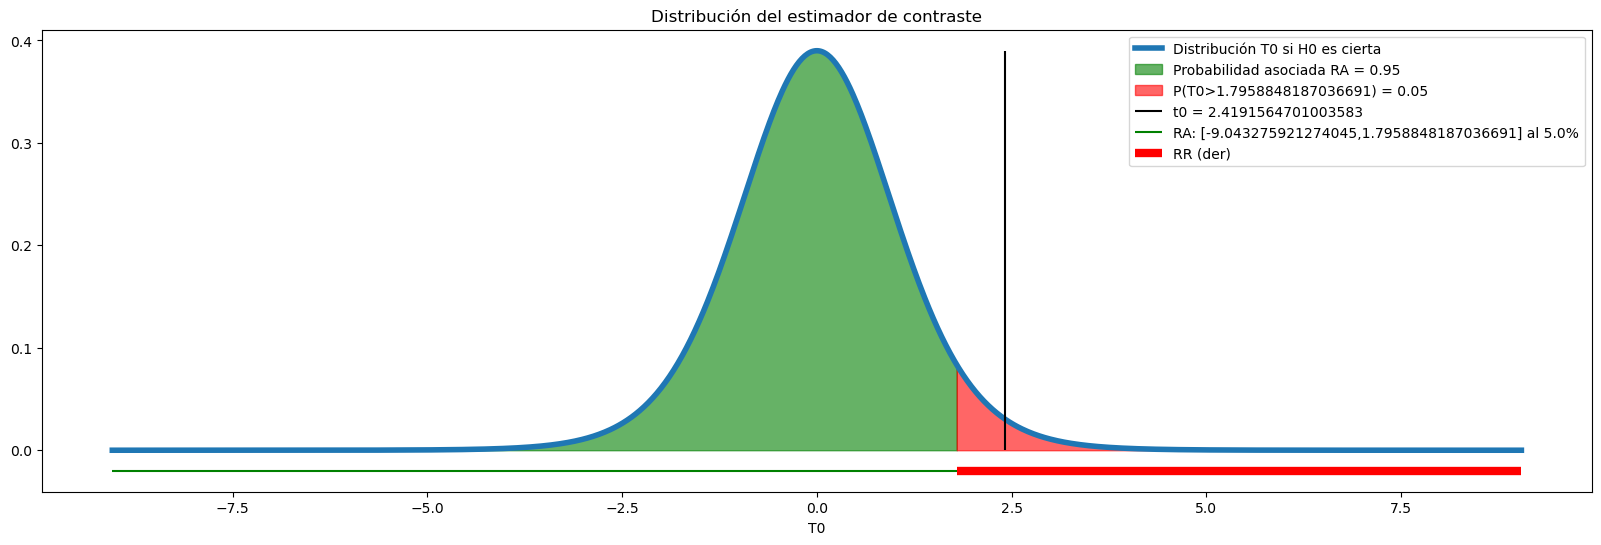

TtestResult(statistic=np.float64(2.4191564701003587), pvalue=np.float64(0.017028866131402823), df=np.int64(11))

In [491]:

def contraste_media_greater(x, mu_0, alfa=0.05):

    alternativa="greater"
    # contraste de la media con varianza desconocida (viene de la chuleta de estadistica, cálculo directo)
    print(f'mu_0 es {mu_0}')
    print(f'H0: hipotesis a priori: el índice medio de los partidos de árbitros que arbitran un solo partido es igual al del resto; H1: es mayor.')

    res = stats.ttest_1samp(x, popmean=mu_0, alternative=alternativa)
    print(f"n={len(x)} | media={np.mean(x):.2f} | mu_0={mu_0:.2f} | t0={res.statistic:.3f} | p-valor={res.pvalue:.3f}")

    t0 = res.statistic
    pvalor = res.pvalue

    print(f'El valor observado del estadistico de contraste es {t0}, con un p-valor asociado igual a {pvalor}.')

    if pvalor < alfa:
        print(f"Se rechaza H0. Se verifica que pvalor = {pvalor} < alfa = {alfa} por lo que el test es estadisticamente significativo y se rechaza la hipotesis nula H0.")
    else:
        print(f"No se rechaza H0 (alfa={alfa}). Se verifica que pvalor = {pvalor} > alfa=  {alfa} por lo que el test NO es estadisticamente significativo y no hay evidencia suficiente que permita rechazar la hipotesis nula H0.")


    # REPRESENTACIÓN GRÁFICA (UNILATERAL) chuleta de primero
    n = len(x)
    x_media = np.mean(x)
    sx = np.std(x, ddof=1) # dividiendo por n-1

    t0 = (x_media - mu_0) / (sx/np.sqrt(n))

    # crea la distribución del estadístico de contraste
    gl = n -1 # grados de libertad
    T0 = stats.t(gl)

    # calculamos el pvalor (caso H1 UNILATERAL)
    pvalor = 1 - T0.cdf(t0)

    # razonando con valores críticos
    # nivel de significación
    alfa = 0.05

    # determina los valores críticos que definen la región de rechazo (unilateral superios)
    t_crit_de = T0.ppf(1-alfa)


    # puntos para representar la distribución y las regiones de aceptación y rechazo
    xmin = T0.ppf(0.000001)
    xmax = T0.ppf(1-0.000001)
    xs = np.linspace(xmin, xmax, 1000)
    xRA = np.linspace(xmin, t_crit_de, 1000)
    xRRde = np.linspace(t_crit_de, xmax, 1000)

    plt.figure(1, figsize=(20, 6))
    plt.plot(xs, T0.pdf(xs), linewidth = 4, label=f'Distribución T0 si H0 es cierta')

    plt.fill_between( xRA, T0.pdf(xRA), color="green", alpha=0.6, label=f'Probabilidad asociada RA = {1-alfa}')
    plt.fill_between( xRRde, T0.pdf(xRRde), color="red", alpha=0.6, label=f'P(T0>{t_crit_de}) = {alfa}')

    plt.vlines(t0, 0, np.max(T0.pdf(xs)), color='black', label=f't0 = {t0}')

    plt.hlines(-0.02, xmin, t_crit_de, color='green', label = f'RA: [{xmin},{t_crit_de}] al {alfa*100}%')
    plt.hlines(-0.02, t_crit_de, xmax, color='red', linewidth = 6, label = f'RR (der)')

    plt.title('Distribución del estimador de contraste')
    plt.xlabel('T0')
    plt.legend()
    plt.show()

    return res


#primero atrobuirle a cada arbitro el numero de partidos que ha arbitrado en el mundial
n_partidos_arbitro = datos_partidos.groupby("arbitro_partido")["index_partido"].transform("count")

#tomo los arbitros  que solo han arbitrado un partido
indice_un_partido = datos_partidos.loc[n_partidos_arbitro == 1, "indice_intervencion"]

#mu_0 será la media del indice de intervencion de los arbitros que han arbitrado más de un partido y frente a ella oponemos los datos de los que solo han arbitrado uno
mu_0 = datos_partidos.loc[n_partidos_arbitro > 1, "indice_intervencion"].mean()

contraste_media_greater(indice_un_partido, mu_0)

CONCLUSIÓN DEL CONTRASTE:
Se rechaza H0 al 5%: los árbitros de un solo partido tienen un índice significativamente mayor de intervencion que los que han aritrado más de uno!

pero ojo:
n = 12 es pequeño, y el índice es algo asímetrico por lo que el resultado puede resultar ilutrativo pero no totalmente concluyente. Por lo que las posibles explicaciones de la nevera o de un ciuerto afán de protagonismo siguen válidas.

In [492]:
def severidad_arbitros_seleccion(seleccion, rondas=None):
    # árbitros que han dirigido partidos de la selección, con la media del índice de intervencion en esos partidos (y ordenamos de menos a más severo)
    df = filtrar_partidos(rondas, seleccion)
    resumen = df.groupby("arbitro_partido").agg(
        partidos=("index_partido", "count"),
        indice_medio=("indice_intervencion", "mean")
    )
    resumen = resumen.sort_values(["indice_medio", "partidos"], ascending=[True, False]).round(2)

    return resumen


def grafico_arbitros_seleccion(seleccion, rondas=None):

    #tomamos solo la seleccion y ronda que queremos y ordenamos segun intervengan los arbotros en ese partido
    df = filtrar_partidos(rondas, seleccion)
    df = df.sort_values("indice_intervencion")

    #creamos una etiqueta que contenga el nombre del arbitro del partido y cual es el partido en cuestion
    df["etiqueta"] = df["arbitro_partido"] + " – " + df["partido"]

    #con esta funcion lo que hacemos es asociar: si el indice es el máximo->es el mas severo; si el indice es igual al minimo -> meno severo y si no, intermedio
    minimo = df["indice_intervencion"].min()
    maximo = df["indice_intervencion"].max()

    def asignar_como_de_severo(row):
        if row["indice_intervencion"] == maximo:
            return "Más severo"
        elif row["indice_intervencion"] == minimo:
            return "Menos severo"
        return "Intermedio"


    
    df["severidad"] = df.apply(asignar_como_de_severo, axis=1)


    fig = px.bar(
        data_frame=df,
        x="indice_intervencion",
        y="etiqueta",
        orientation="h",
        color="severidad",
        hover_name="etiqueta_partido",
        hover_data={"ronda": True, "tarjetas": True, "etiqueta": False, "severidad": False},
        labels={"indice_intervencion": "Índice de Intervención Arbitral", "etiqueta": "Árbitro – partido", "ronda": "Ronda", "tarjetas": "Tarjetas", "severidad": ""},
        color_discrete_map={"Menos severo": "#2ecc71", "Más severo": "#e74c3c", "Intermedio": "#95a5a6"},   #asignamos los colores en funcion de la severidad
        title=f"Árbitros de los partidos de {seleccion} (de menos a más severo)",
    )
    fig.update_layout(yaxis=dict(categoryorder="array", categoryarray=df["etiqueta"].tolist()))
    return fig


In [493]:
severidad_arbitros_seleccion(["Spain"])

,partidos,indice_medio
arbitro_partido,,
Adham Makhadmeh,1,2.0
Espen Eskås,2,2.2
Anthony Taylor,1,3.2
Szymon Marciniak,1,4.2
Michael Oliver,1,4.6
Iván Barton,1,5.4
Slavko Vincic,1,12.2


In [494]:
grafico_arbitros_seleccion(["Spain"])

In [495]:
## finalmente, si queremos determinar cuales son los arbitros que son más veces los más severos pàra una seleccion o los menos severos
## lo que hacemos es que para cada saleccion vamos a buscar el arbitro que fuera el más severo en sus partidos y el que menos
# y finalmente para cada uno de los arbitros en base a esa tabla sacamos cuales son los mñas sseveros para un mayor numero de seleccciones

def tabla_severidad_selecciones(rondas=None):
    # para cada selección buscamos el árbitro menos severo y el árbitro más severo (según la media del índice en sus partidos)

    #empezamos guardando las selecciones, todas sus apariciones en encuentros
    selecciones = []

    for seleccion in partidos["seleccion_local"]:
        if seleccion not in selecciones:
            selecciones.append(seleccion)

    for seleccion in partidos["seleccion_visitante"]:
        if seleccion not in selecciones:
            selecciones.append(seleccion)

    selecciones.sort()

    filas = []

    for seleccion in selecciones:
        s = severidad_arbitros_seleccion([seleccion], rondas) #recordemos que esta funcion devolvía un df (al que llamamos aqui s) con los arbitros de una seleccion ordenados de menos a más severo
        menos = s.iloc[0]   #corresponde a la fila del árbitro menos severo para la seleccion
        mas = s.iloc[-1]    #corresponde a la fila del árbitro MAS severo para la seleccion

        fila = {
            "seleccion": seleccion,
            "partidos": int(s["partidos"].sum()),       #cuantos partidos ha jugado la seleccion
            "arbitro_menos_severo": s.index[0],         #arbitro menos severo
            "indice_menos_severo": menos["indice_medio"],       #y su indice
            "arbitro_mas_severo": s.index[-1],      #arbitro mas severo
            "indice_mas_severo": mas["indice_medio"]        #y su indice
        }

        filas.append(fila)

    return pd.DataFrame(filas)

def coincidencias_arbitros(rondas=None):
    # ahora ya solo queda contar el numero de selecciones (de la trabla que avabamos de crear) para las cuales cada árbitro es el menos severo / el más severo
    tabla = tabla_severidad_selecciones(rondas)
    menos = tabla["arbitro_menos_severo"].value_counts().rename("veces_menos_severo")       #esto devuelve un dataframe en el que las llaves son lo snombres de los arbitros y los valores es el numero de veces que ese arbitro es el menos severo para una seleccion
    mas = tabla["arbitro_mas_severo"].value_counts().rename("veces_mas_severo")             #esto devuelve un dataframe en el que las llaves son lo snombres de los arbitros y los valores es el numero de veces que ese arbitro es el MAS severo para una seleccion
    tabla_coincidencias_arbitros =  pd.concat([menos, mas], axis=1)         #funtamos los dos df que hemos creado en uno solo para que cada arbitro tenga dos columnas que sean el numero de veces que ha sdo el menos y mas severo para una seleccion
    tabla_coincidencias_arbitros = tabla_coincidencias_arbitros.fillna(0).astype(int)       #porque sin el astype int nos deja los numeros de partidos arbitrados como float y queda más bonito int
    tabla_coincidencias_arbitros["partidos_arbitrados"] = tabla_coincidencias_arbitros.index.map(filtrar_partidos(rondas)["arbitro_partido"].value_counts())        # así añadimos el dato del numero de partidos arbitrados por cada arbitro a la tabla resumen
    tabla_coincidencias_arbitros = tabla_coincidencias_arbitros.sort_values(["veces_mas_severo", "veces_menos_severo"], ascending=False)        #y terminamos ordenando para que los mas severos queden arriba
    return tabla_coincidencias_arbitros


In [496]:
tabla_severidad_selecciones().head()

,seleccion,partidos,arbitro_menos_severo,indice_menos_severo,arbitro_mas_severo,indice_mas_severo
0,Algeria,4,Szymon Marciniak,0.6,Slavko Vincic,2.6
1,Argentina,8,Szymon Marciniak,0.6,Slavko Vincic,12.2
2,Australia,4,Drew Fischer,0.4,Alejandro José Hernández,8.4
3,Austria,4,Espen Eskås,1.6,Wilton Sampaio,4.4
4,Belgium,6,Adham Makhadmeh,3.0,Raphael Claus,5.0


In [497]:
coincidencias_arbitros().head(10)

,veces_menos_severo,veces_mas_severo,partidos_arbitrados
Slavko Vincic,1,4,4
Iván Barton,0,4,4
Glenn Nyberg,1,3,3
Wilton Sampaio,0,3,3
Ismail Elfath,0,3,4
Maurizio Mariani,3,2,3
István Kovács,2,2,3
Alireza Faghani,1,2,3
Anthony Taylor,1,2,3
Alejandro José Hernández,0,2,1


OBSERVACIONES
-Vincic y Barton son los más severos en 4 selecciones cada uno, y solo han arbitrado 4 partidos!. PERO OJO, aunque podría parecer que esto sea importante, no se puede tomar como muy significatio tampoco, pues un mismo partido cuenta para dos selecciones, por ejemplo, la final con Vincic (12,2) lo hace “más severo” de España y de Argentina a la vez, llevandolo al principio de la tabla. por otro lado una selección con 3 partidos de grupo solo tiene 3 árbitros y “el más severo” es simplemente el máximo de 3, lo cual tampoco puede llegar a indicar que sea un arbitro más exigente... Es decir, en conclusion, no se puede deciir que haya árbitros que sean “sistemáticamente duros” con selecciones distintas.
-en cuanto al índice, en el fondo consiste en medir el número de tarjetas que saca un árbitro, si son muy tarjeteros o no, pues la influencia de los goles no tiene prácticamente peso, y revisiones de var no hubo muchas (15 en todo el mundial). La influencia de un árbitro va mucho más haya pues de simplememte las tarjetas o las revisiones de var que haga, sino que pasa por otros aspectos del partido: faltas señaladas o no etc que pueden tener más influencia en el partido sinq ue sea posible señalarlo en las bases de datos de las que disponemos.